# Módulo 6: Big Data con PySpark

Facundo Bautista Barbera | TC3009C.601 | 6 de noviembre de 2026, corregido el 22 de noviembre de 2026

## Introducción

Analicé los viajes de taxi amarillo de Nueva York de 2021 a 2024 y comparé tres modelos para estimar cuánto dura un viaje.

En esta versión corregí lo que señaló el profesor. Primero, pasé de 2024 (693 MB) a cuatro años de datos: 48 archivos Parquet que suman 2.42 GB, y el notebook imprime ese total con el tamaño de cada mes. Segundo, las gráficas se ven dentro del notebook, con una paleta apta para daltonismo (Okabe-Ito) y marcadores, tramas o etiquetas para no depender solo del color. Tercero, después de cada paso importante agregué una observación sobre lo que muestran los datos y cómo Spark repartió el trabajo.

## 1. Entorno

Corrí la versión final en una laptop con Arch Linux, 8 núcleos y 15 GB de RAM compartidos con el escritorio, con Spark en modo local y Java 17. La ejecución completa tardó 14 minutos y 21 segundos.

In [1]:
%matplotlib inline
import contextlib
import io
import json
import os
import platform
import re
import shutil
import sys
import time
import urllib.request
from functools import reduce
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyspark
from pyspark import StorageLevel
from pyspark.sql import DataFrame, SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GBTRegressor, LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

JAVA_17 = Path("/usr/lib/jvm/java-17-openjdk-amd64")
if "JAVA_HOME" not in os.environ and JAVA_17.exists():
    os.environ["JAVA_HOME"] = str(JAVA_17)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
SPARK_CONF_DIR = Path("data/spark-conf")
SPARK_CONF_DIR.mkdir(parents=True, exist_ok=True)
(SPARK_CONF_DIR / "log4j2.properties").write_text(
    "rootLogger.level = error\nrootLogger.appenderRef.stdout.ref = console\n"
    "appender.console.type = Console\nappender.console.name = console\nappender.console.target = SYSTEM_ERR\n"
    "appender.console.layout.type = PatternLayout\nappender.console.layout.pattern = %p %c{1}: %m%n\n"
)
os.environ["SPARK_CONF_DIR"] = str(SPARK_CONF_DIR.resolve())
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

YEARS = [2021, 2022, 2023, 2024]
# Okabe-Ito: distinguishable with the common types of color blindness; every chart also uses markers, hatches or labels
OKABE_ITO = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "vermillion": "#D55E00", "sky": "#56B4E9", "grey": "#999999"}
YEAR_COLORS = dict(zip(YEARS, [OKABE_ITO[c] for c in ["blue", "orange", "green", "vermillion"]]))
YEAR_MARKERS = dict(zip(YEARS, ["o", "s", "^", "D"]))
YEAR_HATCHES = dict(zip(YEARS, ["", "//", "..", "xx"]))
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed/trips")
DASHBOARD_DIR = Path("data/dashboard")
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)

# The laptop has 8 cores and 15 GB shared with the desktop; half the cores, a 4 GB heap and 64 MB splits keep it responsive
CORES = 4
spark = (
    SparkSession.builder.appName("nyc-yellow-taxi-2021-2024")
    .master(f"local[{CORES}]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.files.maxPartitionBytes", "64m")
    .config("spark.local.dir", str(Path("data/spark-tmp").resolve()))
    .config("spark.sql.shuffle.partitions", str(CORES * 8))
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.ui.retainedJobs", "5000")
    .config("spark.ui.retainedStages", "5000")
    .getOrCreate()
)
sc = spark.sparkContext
sc.setLogLevel("ERROR")
timings = {}


@contextlib.contextmanager
def step(name):
    sc.setJobDescription(name)
    t0 = time.time()
    yield
    timings[name] = time.time() - t0
    sc.setJobDescription(None)
    print(f"{name}: {timings[name]:.1f} s")


def spark_api(path):
    with urllib.request.urlopen(f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/{path}") as response:
        return json.load(response)


def plan_text(df):
    buffer = io.StringIO()
    with contextlib.redirect_stdout(buffer):
        df.explain()
    return re.sub(r"#\d+L?", "", buffer.getvalue().split("== Initial Plan ==")[0])


def plan_excerpt(df, keywords, width=140):
    lines = [line.rstrip()[:width] for line in plan_text(df).splitlines() if any(k in line for k in keywords)]
    print("\n".join(dict.fromkeys(lines)))


pd.Series({
    "python": platform.python_version(),
    "pyspark": pyspark.__version__,
    "spark": spark.version,
    "java_home": os.environ.get("JAVA_HOME", "system"),
    "master": sc.master,
    "default_parallelism": sc.defaultParallelism,
    "driver_memory": spark.conf.get("spark.driver.memory"),
    "shuffle_partitions": spark.conf.get("spark.sql.shuffle.partitions"),
    "adaptive_execution": spark.conf.get("spark.sql.adaptive.enabled"),
    "max_partition_bytes": spark.conf.get("spark.sql.files.maxPartitionBytes"),
    "broadcast_threshold": spark.conf.get("spark.sql.autoBroadcastJoinThreshold"),
    "spark_ui": sc.uiWebUrl,
})

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


python                                      3.12.16
pyspark                                       4.3.0
spark                                         4.3.0
java_home              /usr/lib/jvm/java-17-openjdk
master                                     local[4]
default_parallelism                               4
driver_memory                                    4g
shuffle_partitions                               32
adaptive_execution                             true
max_partition_bytes                             64m
broadcast_threshold                       10485760b
spark_ui                      http://localhost:4040
dtype: object

**Observación.** Con `local[4]`, el driver y los ejecutores viven en la misma JVM y Spark usa 4 de los 8 núcleos como 4 ranuras de tarea (`default_parallelism`). Dejé la otra mitad libre y limité la memoria del driver a 4 GB porque la laptop también corre el escritorio; en una corrida anterior con más memoria la máquina se trabó. Puse 32 particiones de shuffle (8 por núcleo), divisiones de lectura de 64 MB y dejé AQE activo para que Spark junte las particiones pequeñas después de cada shuffle. Los archivos temporales de Spark van a `data/spark-tmp` porque `/tmp` vive en RAM en este sistema. Spark imprime dos avisos al arrancar; después de `setLogLevel("ERROR")` ya no aparecen más.

## 2. Datos

Usé NYC TLC Yellow Taxi de enero de 2021 a diciembre de 2024: 48 archivos Parquet mensuales. La primera entrega solo usaba 2024 (12 archivos, 693 MB) y no llegaba al mínimo de 1 GB. Con 2022 y 2023 quedaba en 1.94 GB, así que agregué 2021 para pasar de 2 GB. Elegí 2021 y no 2025 para que todos los datos de entrenamiento sean anteriores a diciembre de 2024, el mes que dejo para la prueba. La descarga comprueba el espacio libre y reutiliza los archivos que ya tengo. La tabla muestra el tamaño en MB de cada archivo mensual (filas = año, columnas = mes) y la línea de arriba imprime el total.

Fuente: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

In [2]:
BASE_URL = "https://d37ci6vzurychx.cloudfront.net"
(RAW_DIR / "yellow").mkdir(parents=True, exist_ok=True)

sources = {RAW_DIR / "taxi_zone_lookup.csv": f"{BASE_URL}/misc/taxi_zone_lookup.csv"}
sources.update({
    RAW_DIR / "yellow" / f"yellow_tripdata_{y}-{m:02d}.parquet": f"{BASE_URL}/trip-data/yellow_tripdata_{y}-{m:02d}.parquet"
    for y in YEARS
    for m in range(1, 13)
})
missing = {path: url for path, url in sources.items() if not path.exists()}
free_gb = shutil.disk_usage(RAW_DIR).free / 1e9
if missing and free_gb < 5:
    raise RuntimeError(f"not enough disk space: {free_gb:.1f} GB free")
for path, url in missing.items():
    tmp = path.with_suffix(path.suffix + ".part")
    urllib.request.urlretrieve(url, tmp)
    tmp.rename(path)

files = sorted(f for f in (RAW_DIR / "yellow").glob("yellow_tripdata_*.parquet") if int(f.stem[16:20]) in YEARS)
file_info = pd.DataFrame({
    "file": [f.name for f in files],
    "year": [int(f.stem[16:20]) for f in files],
    "size_mb": [f.stat().st_size / 1e6 for f in files],
})
file_info["month"] = [int(f.stem[21:23]) for f in files]
total_bytes = sum(f.stat().st_size for f in files)
print(f"downloaded now: {len(missing)}, free disk: {free_gb:.1f} GB")
print(f"files: {len(files)}, from {files[0].name} to {files[-1].name}")
print(f"TOTAL PARQUET SIZE: {total_bytes:,} bytes = {total_bytes / 1e9:.2f} GB ({total_bytes / 2**30:.2f} GiB)")
size_table = file_info.pivot(index="year", columns="month", values="size_mb")
size_table["total_mb"] = size_table.sum(axis=1)
size_table.loc["total"] = size_table.sum()
size_table.round(1)

downloaded now: 0, free disk: 173.1 GB
files: 48, from yellow_tripdata_2021-01.parquet to yellow_tripdata_2024-12.parquet
TOTAL PARQUET SIZE: 2,423,425,723 bytes = 2.42 GB (2.26 GiB)


month,1,2,3,4,5,6,7,8,9,10,11,12,total_mb
year,,,,,,,,,,,,,
2021,21.7,21.8,30.0,34.0,38.7,44.1,43.7,43.4,46.1,53.3,53.1,49.6,479.6
2022,38.1,45.6,55.7,55.2,55.6,55.4,49.4,49.7,49.6,57.1,50.1,53.6,615.1
2023,47.7,47.7,56.1,54.2,58.7,55.0,48.4,48.2,47.9,59.0,56.1,56.8,635.7
2024,50.0,50.3,60.1,59.1,62.6,59.9,52.3,51.1,61.2,64.3,60.7,61.5,693.0
total,157.5,165.5,201.9,202.6,215.5,214.3,193.7,192.4,204.8,233.7,220.0,221.6,2423.4


Los archivos no tienen todos el mismo esquema. Si leo la carpeta completa de una vez, Spark toma el esquema de un archivo y falla o lee mal los demás. Revisé los tipos de cada archivo y dejé solo las columnas que cambian:

In [3]:
monthly_dfs = {f: spark.read.parquet(str(f)) for f in files}
schemas = pd.DataFrame({f.stem[16:]: dict(df.dtypes) for f, df in monthly_dfs.items()}).T.fillna("-")
varying = schemas.loc[:, schemas.nunique() > 1]
(
    varying.reset_index(names="month")
    .groupby(list(varying.columns))["month"].agg(["first", "last", "count"])
    .reset_index().sort_values("first").set_index(["first", "last", "count"]).T
)

first,2021-01,2023-02
last,2023-01,2024-12
count,25,23
VendorID,bigint,int
passenger_count,double,bigint
RatecodeID,double,bigint
PULocationID,bigint,int
DOLocationID,bigint,int
airport_fee,double,-
Airport_fee,-,double


Hay dos versiones. Hasta enero de 2023, los conteos y las zonas vienen como `double` o `bigint` y la columna se llama `airport_fee`. Desde febrero de 2023 vienen como `int` o `bigint` y la columna se llama `Airport_fee`. Leí cada archivo por separado, renombré y casteé las columnas a un esquema común y uní los 48 DataFrames con `unionByName`. También agregué el nombre del archivo como columna para contar las filas de cada mes.

In [4]:
COMMON_SCHEMA = {
    "VendorID": "int",
    "tpep_pickup_datetime": "timestamp_ntz",
    "tpep_dropoff_datetime": "timestamp_ntz",
    "passenger_count": "int",
    "trip_distance": "double",
    "RatecodeID": "int",
    "store_and_fwd_flag": "string",
    "PULocationID": "int",
    "DOLocationID": "int",
    "payment_type": "int",
    "fare_amount": "double",
    "extra": "double",
    "mta_tax": "double",
    "tip_amount": "double",
    "tolls_amount": "double",
    "improvement_surcharge": "double",
    "total_amount": "double",
    "congestion_surcharge": "double",
    "airport_fee": "double",
}


def standardize(df, path):
    by_lower = {c.lower(): c for c in df.columns}
    return df.select(
        *[F.col(by_lower[name.lower()]).cast(dtype).alias(name) for name, dtype in COMMON_SCHEMA.items()],
        F.lit(path.name).alias("source_file"),
    )


raw = reduce(DataFrame.unionByName, [standardize(df, f) for f, df in monthly_dfs.items()])
zones = spark.read.csv(str(RAW_DIR / "taxi_zone_lookup.csv"), header=True, inferSchema=True)
raw.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)
 |-- source_file: string (nullable = false)



In [5]:
with step("Conteo de filas por archivo"):
    rows_by_file = raw.groupBy("source_file").count().toPandas()

file_info = file_info.merge(rows_by_file.rename(columns={"source_file": "file", "count": "rows"}), on="file")
raw_rows = int(file_info["rows"].sum())
parquet_bytes = sum(f.stat().st_size for f in files)
print(f"parquet files: {len(files)}")
print(f"parquet size: {parquet_bytes / 1e9:.2f} GB ({parquet_bytes / 2**30:.2f} GiB)")
print(f"rows read by spark: {raw_rows:,}")
print(f"input partitions: {raw.rdd.getNumPartitions()}")

Conteo de filas por archivo: 5.3 s
parquet files: 48
parquet size: 2.42 GB (2.26 GiB)
rows read by spark: 150,040,352


input partitions: 192


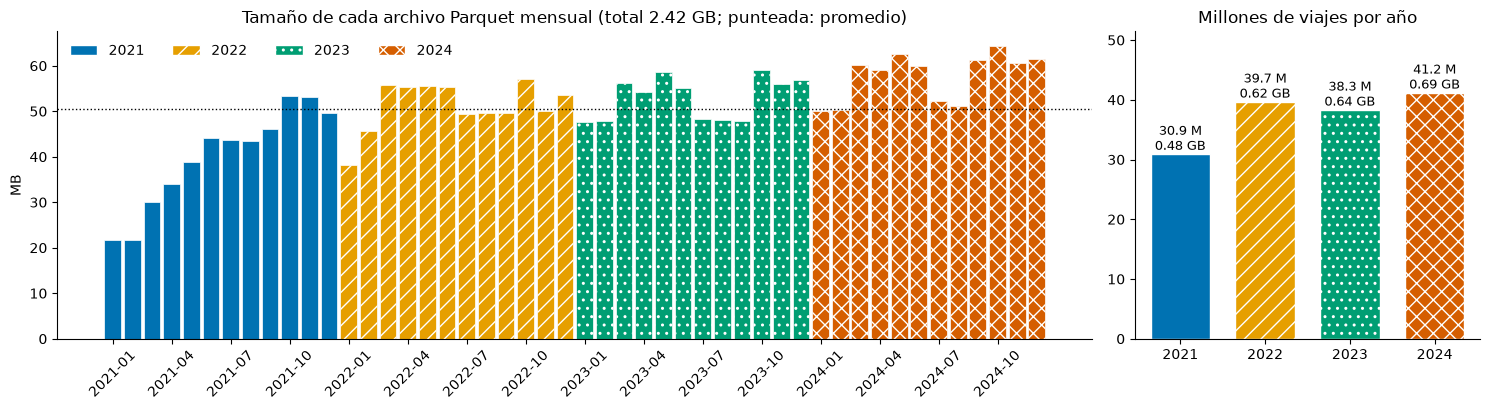

In [6]:
by_year = file_info.groupby("year").agg(size_gb=("size_mb", lambda s: s.sum() / 1000), rows_m=("rows", lambda s: s.sum() / 1e6))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [3, 1]})
axes[0].bar(range(len(file_info)), file_info["size_mb"], color=file_info["year"].map(YEAR_COLORS), width=0.85, edgecolor="white", linewidth=0.5)
for bar, year in zip(axes[0].patches, file_info["year"]):
    bar.set_hatch(YEAR_HATCHES[year])
axes[0].axhline(file_info["size_mb"].mean(), color="black", linestyle=":", linewidth=1)
axes[0].set_xticks(range(0, len(file_info), 3), file_info["file"].str[16:23].iloc[::3], rotation=45)
axes[0].set_ylabel("MB")
axes[0].set_title(f"Tamaño de cada archivo Parquet mensual (total {parquet_bytes / 1e9:.2f} GB; punteada: promedio)")
axes[0].legend(
    handles=[plt.Rectangle((0, 0), 1, 1, facecolor=YEAR_COLORS[y], hatch=YEAR_HATCHES[y], edgecolor="white") for y in YEARS],
    labels=YEARS, frameon=False, ncol=4,
)
axes[1].bar(by_year.index.astype(str), by_year["rows_m"], color=[YEAR_COLORS[y] for y in by_year.index], width=0.7, edgecolor="white")
for bar, year in zip(axes[1].patches, by_year.index):
    bar.set_hatch(YEAR_HATCHES[year])
for i, (gb, rows) in enumerate(zip(by_year["size_gb"], by_year["rows_m"])):
    axes[1].text(i, rows, f"{rows:.1f} M\n{gb:.2f} GB", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, by_year["rows_m"].max() * 1.25)
axes[1].set_title("Millones de viajes por año")
plt.tight_layout()
plt.show()

**Observación.** Spark leyó 150,040,352 filas de los 48 archivos, que pesan 2.42 GB en total. El conteo por archivo solo necesita el número de filas de cada uno, por eso tarda unos segundos. `raw` tiene 192 particiones, pero cada archivo de la TLC trae un solo *row group* y Spark no puede partir un row group. Como leí cada archivo por separado, Spark calculó un tamaño de división de unos 13 MB (el tamaño del archivo entre 4 núcleos) y creó 4 particiones por archivo, de las que solo una tiene datos. En la práctica, 48 tareas hacen el trabajo pesado y se reparten en 12 rondas sobre los 4 núcleos. `unionByName` no mueve datos: solo concatena las particiones de los 48 DataFrames, sin shuffle. En la gráfica, las tramas distinguen los años sin depender del color: 2021 pesa menos (30.9 M viajes) porque la demanda todavía se estaba recuperando de la pandemia, y desde 2022 cada año ronda los 40 M viajes.

In [7]:
zones.limit(5).toPandas()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


## 3. Calidad de los datos

Calculé las reglas de calidad en una sola agregación sobre todas las filas.

In [8]:
with_duration = raw.withColumn(
    "duration_min",
    F.expr("timestampdiff(SECOND, tpep_pickup_datetime, tpep_dropoff_datetime)") / 60,
)

checks = {
    "null_passenger_count": F.col("passenger_count").isNull(),
    "null_ratecode": F.col("RatecodeID").isNull(),
    "pickup_outside_2021_2024": ~F.col("tpep_pickup_datetime").between("2021-01-01", "2024-12-31 23:59:59"),
    "duration_below_1_min": F.col("duration_min") < 1,
    "duration_above_180_min": F.col("duration_min") > 180,
    "distance_zero_or_less": F.col("trip_distance") <= 0,
    "distance_above_100_mi": F.col("trip_distance") > 100,
    "fare_below_3_usd": F.col("fare_amount") < 3,
    "fare_above_500_usd": F.col("fare_amount") > 500,
    "unknown_zone": F.col("PULocationID").isin(264, 265) | F.col("DOLocationID").isin(264, 265),
}

quality_df = with_duration.agg(*[F.sum(cond.cast("int")).alias(name) for name, cond in checks.items()])
with step("Perfil de calidad"):
    quality = quality_df.toPandas().T
quality.columns = ["rows"]
quality["pct"] = (quality["rows"] / raw_rows * 100).round(2)
plan_excerpt(quality_df, ["AdaptiveSparkPlan", "HashAggregate", "Exchange", "Union"])
quality

Perfil de calidad: 20.5 s
AdaptiveSparkPlan isFinalPlan=true
   +- *(2) HashAggregate(keys=[], functions=[sum(cast(isnull(passenger_count) as int)), sum(cast(isnull(RatecodeID) as int)), sum(cast(((tpe
         +- Exchange SinglePartition, ENSURE_REQUIREMENTS, [plan_id=2065]
            +- *(1) HashAggregate(keys=[], functions=[partial_sum(cast(isnull(passenger_count) as int)), partial_sum(cast(isnull(RatecodeID)
               +- *(1) Union


,rows,pct
null_passenger_count,8247586,5.50
null_ratecode,8247586,5.50
pickup_outside_2021_2024,964,0.00
duration_below_1_min,1865300,1.24
duration_above_180_min,168248,0.11
distance_zero_or_less,2531633,1.69
distance_above_100_mi,7202,0.00
fare_below_3_usd,2001521,1.33
fare_above_500_usd,1450,0.00
unknown_zone,2359792,1.57


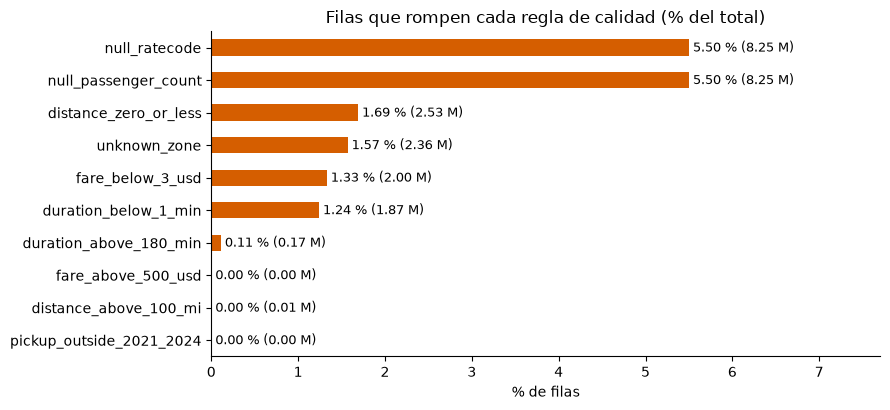

In [9]:
quality_plot = quality["pct"].sort_values()
ax = quality_plot.plot.barh(figsize=(9, 4.2), color=OKABE_ITO["vermillion"], title="Filas que rompen cada regla de calidad (% del total)")
for i, (pct, rows) in enumerate(zip(quality_plot, quality.loc[quality_plot.index, "rows"])):
    ax.text(pct, i, f" {pct:.2f} % ({rows / 1e6:.2f} M)", va="center", fontsize=9)
ax.set_xlim(0, quality_plot.max() * 1.4)
ax.set_xlabel("% de filas")
plt.tight_layout()
plt.show()


**Observación.** La agregación recorre las 150 M filas en una sola pasada. En el plan se ve el patrón de dos fases. Primero, cada partición calcula sumas parciales (`partial_sum` en el `HashAggregate` de abajo). Después, un `Exchange SinglePartition` junta esos resultados, que son una fila por tarea, y el `HashAggregate` de arriba da el total. Así, el shuffle es mínimo aunque la tabla sea grande. En la gráfica, el problema más común son los nulos de `passenger_count` y `RatecodeID`, que son las mismas 8.25 M filas (5.5 %). No las quité porque el modelo no usa `passenger_count` y a `ratecode` le pongo 99 cuando falta. Las reglas que sí filtran (distancia, zona desconocida, tarifa y duración) afectan cada una entre 0.1 % y 1.7 % de las filas, y solo 964 viajes caen fuera de 2021 a 2024.

## 4. Limpieza y variables

Conservé viajes que empiezan entre 2021 y 2024, con duración de 1 a 180 minutos, distancia de 0.1 a 100 millas, tarifa de 3 a 500 USD, velocidad de 1 a 70 mph y zonas conocidas. Son las mismas reglas de la primera entrega; solo cambió el rango de fechas. Después agregué las variables de fecha, hora y viaje y guardé el resultado particionado por año y mes.

Pasé de 150.0 M viajes originales (150,040,352) a 143.1 M limpios (143,116,354); quité el 4.61 %.

In [10]:
AIRPORT_ZONES = [1, 132, 138]
DOW_NAMES = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
PAYMENT_NAMES = {0: "Flex fare", 1: "Tarjeta", 2: "Efectivo", 3: "Sin cargo", 4: "Disputa", 5: "Desconocido", 6: "Anulado"}

pu_zones = F.broadcast(zones.select(
    F.col("LocationID").alias("PULocationID"),
    F.col("Borough").alias("pu_borough"),
    F.col("Zone").alias("pu_zone"),
))
do_zones = F.broadcast(zones.select(
    F.col("LocationID").alias("DOLocationID"),
    F.col("Borough").alias("do_borough"),
    F.col("Zone").alias("do_zone"),
))
payment_map = F.create_map(*[x for k, v in PAYMENT_NAMES.items() for x in (F.lit(k), F.lit(v))])

clean = (
    with_duration
    .withColumn("speed_mph", F.col("trip_distance") / (F.col("duration_min") / 60))
    .filter(F.col("tpep_pickup_datetime").between("2021-01-01", "2024-12-31 23:59:59"))
    .filter(F.col("duration_min").between(1, 180))
    .filter(F.col("trip_distance").between(0.1, 100))
    .filter(F.col("fare_amount").between(3, 500) & (F.col("total_amount") > 0))
    .filter(F.col("speed_mph").between(1, 70))
    .filter(~F.col("PULocationID").isin(264, 265) & ~F.col("DOLocationID").isin(264, 265))
    .withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
    .withColumn("pickup_year", F.year("tpep_pickup_datetime"))
    .withColumn("pickup_month", F.month("tpep_pickup_datetime"))
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
    .withColumn("pickup_dow", ((F.dayofweek("tpep_pickup_datetime") + 5) % 7) + 1)
    .withColumn("is_weekend", (F.col("pickup_dow") >= 6).cast("int"))
    .withColumn("ratecode", F.coalesce(F.col("RatecodeID"), F.lit(99)).cast("int"))
    .withColumn(
        "is_airport",
        (F.col("PULocationID").isin(AIRPORT_ZONES) | F.col("DOLocationID").isin(AIRPORT_ZONES)).cast("int"),
    )
    .withColumn(
        "tip_pct",
        F.when(F.col("payment_type") == 1, F.least(F.col("tip_amount") / F.col("fare_amount") * 100, F.lit(100.0))),
    )
    .withColumn("payment_name", F.coalesce(payment_map[F.col("payment_type")], F.lit("Desconocido")))
    .join(pu_zones, "PULocationID")
    .join(do_zones, "DOLocationID")
    .select(
        "tpep_pickup_datetime", "pickup_date", "pickup_year", "pickup_month", "pickup_hour", "pickup_dow", "is_weekend",
        "PULocationID", "DOLocationID", "pu_borough", "pu_zone", "do_borough", "do_zone",
        "trip_distance", "duration_min", "speed_mph", "passenger_count", "ratecode", "is_airport",
        "payment_type", "payment_name", "fare_amount", "tip_amount", "tip_pct", "total_amount",
    )
)

plan_excerpt(clean, ["BroadcastHashJoin", "BroadcastExchange", "Exchange", "Union"])
with step("Limpieza y escritura Parquet"):
    clean.write.mode("overwrite").partitionBy("pickup_year", "pickup_month").parquet(str(PROCESSED_DIR))

written = list(PROCESSED_DIR.rglob("*.parquet"))
print(f"files written: {len(written)} in {len({p.parent for p in written})} year/month folders")

   +- BroadcastHashJoin [DOLocationID], [DOLocationID], Inner, BuildRight, false, false
      :  +- BroadcastHashJoin [PULocationID], [PULocationID], Inner, BuildRight, false, false
      :     :- Union
      :     +- BroadcastExchange HashedRelationBroadcastMode(List(cast(input[0, int, true] as bigint)),false), [plan_id=3074]
      +- BroadcastExchange HashedRelationBroadcastMode(List(cast(input[0, int, true] as bigint)),false), [plan_id=3078]


Limpieza y escritura Parquet: 143.6 s
files written: 217 in 48 year/month folders


**Observación.** Las dos uniones con la tabla de zonas son `BroadcastHashJoin`. La tabla tiene 265 filas, así que Spark manda una copia a cada tarea (`BroadcastExchange`) y los viajes no se mueven. En el plan no aparece ningún `Exchange` sobre los viajes antes de escribir. Decidí no hacer `repartition` antes de `partitionBy`. Cada archivo de entrada corresponde casi completo a un mes, así que cada tarea escribe casi todo en la carpeta de su mes y me ahorro un shuffle de 143 M filas. El costo es que quedan 217 archivos en 48 carpetas, porque algunos archivos traen viajes de otros meses. Es el paso más pesado sobre los datos completos: lee las 19 columnas, filtra, une, calcula variables y comprime todo otra vez.

In [11]:
trips = spark.read.parquet(str(PROCESSED_DIR))
december = trips.filter((F.col("pickup_year") == 2024) & (F.col("pickup_month") == 12))
with step("Lectura de diciembre 2024 con poda de particiones"):
    december_rows = december.count()
print(re.search(r"PartitionFilters: \[[^\]]*\]", plan_text(december)).group())

# With a 4 GB heap, caching 143 M rows in memory runs out of heap; the cache lives on local disk instead
trips = trips.persist(StorageLevel.DISK_ONLY)
with step("Persistir viajes limpios"):
    clean_rows = trips.count()

cached = max(spark_api("storage/rdd"), key=lambda r: r["memoryUsed"] + r["diskUsed"])
pd.Series({
    "raw_rows": raw_rows,
    "clean_rows": clean_rows,
    "removed_rows": raw_rows - clean_rows,
    "removed_pct": round((raw_rows - clean_rows) / raw_rows * 100, 2),
    "december_2024_rows": december_rows,
    "processed_size_mb": round(sum(p.stat().st_size for p in written) / 1e6, 1),
    "processed_partitions": trips.rdd.getNumPartitions(),
    "cached_partitions": f"{cached['numCachedPartitions']} / {cached['numPartitions']}",
    "cache_memory_mb": round(cached["memoryUsed"] / 1e6, 1),
    "cache_disk_mb": round(cached["diskUsed"] / 1e6, 1),
})

Lectura de diciembre 2024 con poda de particiones: 0.2 s
PartitionFilters: [isnotnull(pickup_year), isnotnull(pickup_month), (pickup_year = 2024), (pickup_mo..., PushedFilters: []


Persistir viajes limpios: 109.3 s


raw_rows                150040352
clean_rows              143116354
removed_rows              6923998
removed_pct                  4.61
december_2024_rows        3451535
processed_size_mb          4028.7
processed_partitions           78
cached_partitions         78 / 78
cache_memory_mb               0.0
cache_disk_mb              6293.3
dtype: object

**Observación.** El particionado por año y mes sirve al leer. Para contar diciembre de 2024, el plan muestra `PartitionFilters` con `pickup_year = 2024` y `pickup_month = 12`, así que Spark solo abre esa carpeta y responde en menos de un segundo. Después persistí `trips` porque lo uso en todos los agregados y en el modelo. Con `MEMORY_AND_DISK` y 4 GB de memoria el driver se quedó sin heap al construir el caché, así que usé `DISK_ONLY`: el caché columnar ocupa 6.3 GB en el disco local y 0 en memoria. Aun así conviene, porque leerlo evita repetir la lectura de los 4.0 GB de Parquet y la decodificación de las columnas. Las 78 particiones salen de dividir los 4.0 GB en bloques de hasta 64 MB (`maxPartitionBytes`).

In [12]:
trips.select("trip_distance", "duration_min", "speed_mph", "fare_amount", "tip_pct", "total_amount").summary(
    "mean", "stddev", "min", "25%", "50%", "75%", "max"
).toPandas().set_index("summary")

,trip_distance,duration_min,speed_mph,fare_amount,tip_pct,total_amount
summary,,,,,,
mean,3.3813786147039373,15.871137883724975,11.562579129815008,16.798832685746724,25.435158122755535,24.624328107365404
stddev,4.213142757365548,12.653266288042749,6.343155469771054,14.589952382082588,11.079106174742893,18.75623318417129
min,0.1,1.0,1.0,3.0,0.0,1.0
25%,1.1,7.566666666666666,7.5,8.0,20.952380952380953,13.8
50%,1.84,12.35,9.982532751091702,12.0,26.249999999999996,18.4
75%,3.41,19.916666666666668,13.636363636363637,19.1,30.85714285714286,26.8
max,99.26,180.0,70.0,500.0,100.0,1737.18


**Observación.** El viaje típico es corto: la mediana es de 1.84 millas y 12.4 minutos, a unas 10 mph. Las medias son más altas que las medianas (3.38 millas y 15.9 minutos) porque los viajes al aeropuerto alargan la cola derecha. La propina promedio es de 25.4 % de la tarifa, pero solo cuenta pagos con tarjeta, porque en efectivo la propina no queda registrada. El máximo de `total_amount` (1,737 USD) pasa el filtro porque la tarifa está limitada a 500 USD, pero el total incluye peajes y recargos. Son pocos casos y no cambian los promedios.

## 5. Agregados y gráficas

Calculé los agregados con Spark y solo pasé a pandas los resultados, que son pequeños. El tablero publicado en Tableau Public se armó con los datos de 2024 de la primera entrega, así que los CSV del tablero (`daily_summary`, `hourly_by_weekday`, `monthly_by_payment`, `pickup_zones`, `borough_flows` y `top_routes`) los sigo generando solo con 2024. Se guardan en `data/dashboard/`, que no se sube al repositorio. Al cambiar el rango de fechas, estos CSV cambian en 4 viajes de 39 millones: viajes del 1 y del 3 de enero de 2024 que venían en el archivo de diciembre de 2023. Las métricas del modelo sí cambian, porque ahora entrena con cuatro años (ver la sección 10). Para el análisis de varios años agregué `monthly_by_year.csv`.

In [13]:
def trip_metrics():
    return [
        F.count("*").alias("trips"),
        F.round(F.avg("duration_min"), 2).alias("avg_duration_min"),
        F.round(F.avg("trip_distance"), 2).alias("avg_distance_mi"),
        F.round(F.avg("speed_mph"), 2).alias("avg_speed_mph"),
        F.round(F.avg("fare_amount"), 2).alias("avg_fare_usd"),
        F.round(F.avg("tip_pct"), 2).alias("avg_tip_pct"),
        F.round(F.sum("total_amount"), 2).alias("revenue_usd"),
    ]


def export_csv(df, name):
    pdf = df.toPandas()
    pdf.to_csv(DASHBOARD_DIR / f"{name}.csv", index=False)
    return pdf


dow_name = F.element_at(F.array(*[F.lit(n) for n in DOW_NAMES]), F.col("pickup_dow"))

daily_df = (
    trips.groupBy("pickup_date").agg(*trip_metrics())
    .withColumn("pickup_dow", ((F.dayofweek("pickup_date") + 5) % 7) + 1)
    .withColumn("dow_name", dow_name)
    .orderBy("pickup_date")
)
with step("Agregado diario 2021-2024"):
    daily_all = daily_df.toPandas()
daily_all["pickup_date"] = pd.to_datetime(daily_all["pickup_date"])
daily = daily_all[daily_all["pickup_date"].dt.year == 2024]
daily.to_csv(DASHBOARD_DIR / "daily_summary.csv", index=False, date_format="%Y-%m-%d")
print(f"days: {len(daily_all)}, days in dashboard csv: {len(daily)}")
plan_excerpt(daily_df, ["AdaptiveSparkPlan", "HashAggregate", "Exchange", "AQEShuffleRead", "InMemoryTableScan"])

Agregado diario 2021-2024: 7.3 s
days: 1461, days in dashboard csv: 366
AdaptiveSparkPlan isFinalPlan=true
      +- AQEShuffleRead coalesced
            +- Exchange rangepartitioning(pickup_date ASC NULLS FIRST, 32), ENSURE_REQUIREMENTS, [plan_id=5346]
                  +- *(2) HashAggregate(keys=[pickup_date], functions=[count(1), avg(duration_min), avg(trip_distance), avg(speed_mph), avg(
                     +- AQEShuffleRead coalesced
                           +- Exchange hashpartitioning(pickup_date, 32), ENSURE_REQUIREMENTS, [plan_id=5311]
                              +- *(1) HashAggregate(keys=[pickup_date], functions=[partial_count(1), partial_avg(duration_min), partial_avg(
                                    +- InMemoryTableScan [pickup_date, trip_distance, duration_min, speed_mph, fare_amount, tip_pct, total_a


**Observación.** El agregado diario sale del caché (`InMemoryTableScan`, aunque el caché esté en disco) y repite el patrón parcial y final, ahora con un `Exchange hashpartitioning(pickup_date, 32)`: cada fecha se manda a una de las 32 particiones de shuffle. Como solo hay 1,461 días, AQE juntó las particiones casi vacías (`AQEShuffleRead coalesced`) antes de la agregación final. El `orderBy` agrega un segundo shuffle por rangos (`rangepartitioning`). En la tabla de la sección 8 se ve que este paso movió menos de 1 MB entre tareas, aunque recorrió 143 M filas. El filtro `pickup_year == 2024` para el tablero también sale del caché, así que no vuelvo a leer el Parquet.

In [14]:
trips_2024 = trips.filter(F.col("pickup_year") == 2024)

with step("Agregados del tablero 2024"):
    hourly = export_csv(
        trips_2024.groupBy("pickup_dow", "pickup_hour").agg(*trip_metrics())
        .withColumn("dow_name", dow_name).orderBy("pickup_dow", "pickup_hour"),
        "hourly_by_weekday",
    )
    monthly_payment = export_csv(
        trips_2024.groupBy("pickup_month", "payment_name").agg(*trip_metrics()).orderBy("pickup_month", "payment_name"),
        "monthly_by_payment",
    )
    pickup_zones = export_csv(
        trips_2024.groupBy("PULocationID", "pu_borough", "pu_zone").agg(*trip_metrics())
        .withColumnRenamed("PULocationID", "location_id").orderBy(F.desc("trips")),
        "pickup_zones",
    )
    borough_flows = export_csv(
        trips_2024.groupBy("pu_borough", "do_borough").agg(*trip_metrics()).orderBy(F.desc("trips")),
        "borough_flows",
    )
    top_routes = export_csv(
        trips_2024.groupBy("pu_borough", "pu_zone", "do_borough", "do_zone").agg(*trip_metrics())
        .filter(F.col("trips") >= 1000).orderBy(F.desc("trips")).limit(500),
        "top_routes",
    )

with step("Agregados de varios años"):
    monthly_year = export_csv(
        trips.groupBy("pickup_year", "pickup_month").agg(*trip_metrics()).orderBy("pickup_year", "pickup_month"),
        "monthly_by_year",
    )
    hour_type = trips.groupBy("is_weekend", "pickup_hour").count().toPandas()

top_routes.head(10)

Agregados del tablero 2024: 28.2 s


Agregados de varios años: 10.5 s


,pu_borough,pu_zone,do_borough,do_zone,trips,avg_duration_min,avg_distance_mi,avg_speed_mph,avg_fare_usd,avg_tip_pct,revenue_usd
0,Manhattan,Upper East Side South,Manhattan,Upper East Side North,275503,7.37,1.05,9.65,8.89,28.87,4336176.53
1,Manhattan,Upper East Side North,Manhattan,Upper East Side South,237392,8.18,1.04,8.42,9.40,27.88,3837262.87
2,Manhattan,Upper East Side South,Manhattan,Upper East Side South,180673,5.94,0.65,7.56,7.36,31.97,2504613.00
3,Manhattan,Upper East Side North,Manhattan,Upper East Side North,176775,4.87,0.64,8.73,6.70,33.14,2316328.69
4,Manhattan,Midtown Center,Manhattan,Upper East Side South,129569,9.80,1.06,7.39,10.32,27.82,2265111.33
5,Manhattan,Upper East Side South,Manhattan,Midtown Center,114721,10.55,1.04,6.91,10.84,26.85,2027221.76
6,Manhattan,Midtown Center,Manhattan,Upper East Side North,108083,13.86,1.93,9.48,14.34,24.64,2408463.15
7,Manhattan,Upper East Side South,Manhattan,Midtown East,105187,9.06,0.98,7.63,9.82,28.16,1746376.61
8,Manhattan,Upper West Side South,Manhattan,Lincoln Square East,103331,6.19,0.88,9.31,7.94,30.95,1507982.20
9,Manhattan,Lincoln Square East,Manhattan,Upper West Side South,103117,6.25,0.99,10.18,8.13,30.91,1546246.52


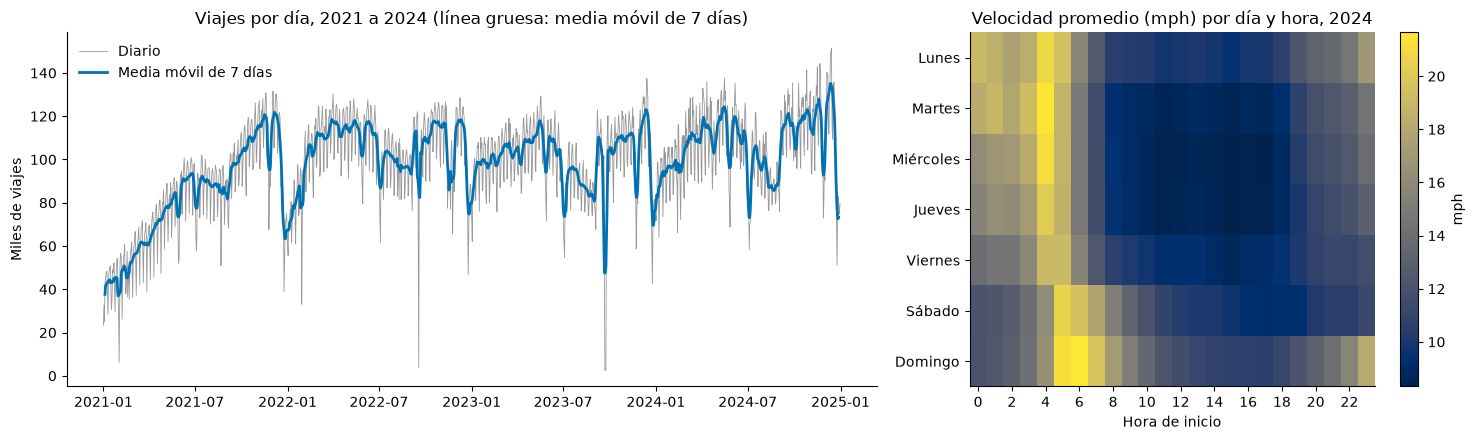

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})

axes[0].plot(daily_all["pickup_date"], daily_all["trips"] / 1000, linewidth=0.6, color=OKABE_ITO["grey"], label="Diario")
axes[0].plot(daily_all["pickup_date"], daily_all["trips"].rolling(7, center=True).mean() / 1000, linewidth=2, color=OKABE_ITO["blue"], label="Media móvil de 7 días")
axes[0].set_title("Viajes por día, 2021 a 2024 (línea gruesa: media móvil de 7 días)")
axes[0].set_ylabel("Miles de viajes")
axes[0].legend(frameon=False)

heat = hourly.pivot(index="pickup_dow", columns="pickup_hour", values="avg_speed_mph")
im = axes[1].imshow(heat, aspect="auto", cmap="cividis")
axes[1].set_yticks(range(7), DOW_NAMES)
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel("Hora de inicio")
axes[1].set_title("Velocidad promedio (mph) por día y hora, 2024")
fig.colorbar(im, ax=axes[1], label="mph")
plt.tight_layout()
plt.show()

**Observación.** La serie diaria sube durante 2021, de unos 40 mil a más de 110 mil viajes por día, y desde 2022 la media móvil se mueve entre unos 85 y 135 mil. La línea gris es el valor diario y la azul gruesa la media móvil, así que se distinguen por grosor además de color. Las caídas más fuertes son el 1 de febrero de 2021 (nevada), los días festivos (el 25 de diciembre de 2024 es el día con menos viajes de ese año, 51 mil) y dos huecos que parecen faltantes en los registros de la TLC: el 18 de septiembre de 2022 y del 22 al 24 de septiembre de 2023. No los quité porque son 4 días de 1,461. En el mapa de calor (paleta cividis, que se lee igual con daltonismo y en escala de grises), la velocidad es más alta de 4 a 6 de la mañana (unas 20 mph) y más baja entre semana de 9 a 18 h (cerca de 9 mph).

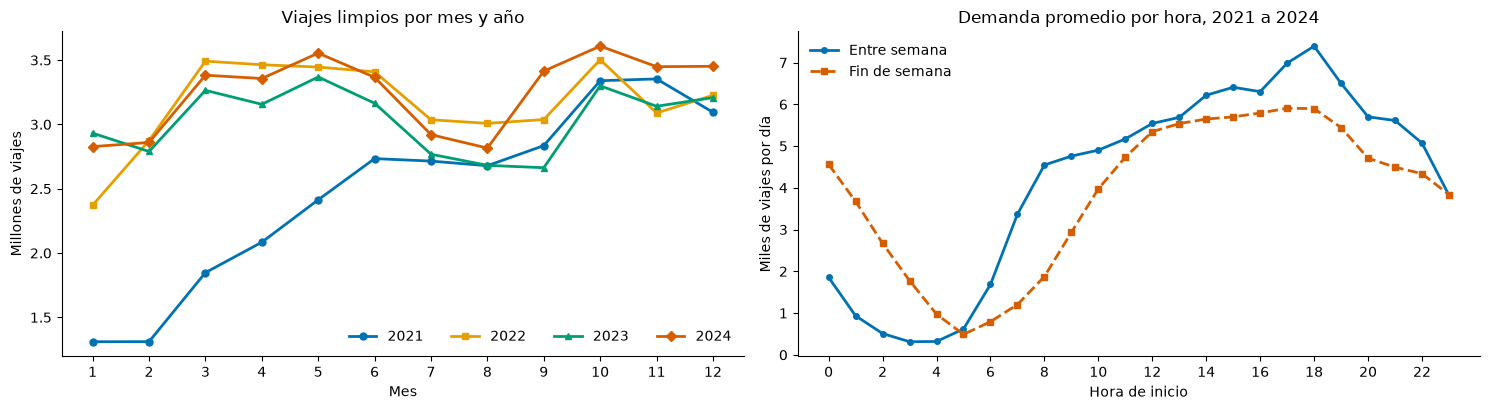

In [16]:
days_by_type = daily_all.assign(is_weekend=(daily_all["pickup_dow"] >= 6).astype(int)).groupby("is_weekend").size()
hour_type["trips_per_day"] = hour_type["count"] / hour_type["is_weekend"].map(days_by_type)
hour_curve = hour_type.pivot(index="pickup_hour", columns="is_weekend", values="trips_per_day")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for year in YEARS:
    data = monthly_year[monthly_year["pickup_year"] == year]
    axes[0].plot(data["pickup_month"], data["trips"] / 1e6, marker=YEAR_MARKERS[year], markersize=5, linewidth=2, color=YEAR_COLORS[year], label=year)
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Millones de viajes")
axes[0].set_title("Viajes limpios por mes y año")
axes[0].legend(frameon=False, ncol=4)

axes[1].plot(hour_curve.index, hour_curve[0] / 1000, linewidth=2, color=OKABE_ITO["blue"], marker="o", markersize=4, label="Entre semana")
axes[1].plot(hour_curve.index, hour_curve[1] / 1000, linewidth=2, color=OKABE_ITO["vermillion"], linestyle="--", marker="s", markersize=4, label="Fin de semana")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel("Hora de inicio")
axes[1].set_ylabel("Miles de viajes por día")
axes[1].set_title("Demanda promedio por hora, 2021 a 2024")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

**Observación.** Cada año tiene su propio marcador. 2021 empieza en 1.31 M viajes al mes y sube durante todo el año. Desde 2022 los años se parecen: bajan en enero y en julio y agosto, y suben en marzo a mayo y en octubre. 2024 es el año más alto en mayo y de septiembre a diciembre, con un máximo de 3.61 M viajes en octubre. Entre semana (línea continua) el pico es a las 18 h, con unos 7.4 mil viajes por día en esa hora. En fin de semana (línea punteada) hay más viajes de madrugada y el mínimo es a las 5 h.

## 6. Modelo

Usé origen, destino, distancia y variables temporales para estimar la duración. Mantuve diciembre de 2024 como prueba y entrené con todo lo anterior, de enero de 2021 a noviembre de 2024. Como ahora hay varios años, agregué el año y el mes como variables para que el modelo distinga, por ejemplo, el tráfico más ligero de 2021. La distancia es la registrada; para predecir antes del viaje necesitaría una estimación de la ruta.

Las codificaciones por ruta y por zona-hora las calculé con todos los viajes de entrenamiento. Para entrenar los modelos bajé la fracción de muestreo de 6 % a 1.5 %. Así la muestra queda en unos 2 millones de viajes, parecida a la de la primera entrega, y el tiempo de entrenamiento no se multiplica por cuatro.

In [17]:
SMOOTHING = 50
SEED = 42
SAMPLE_FRACTION = 0.015

is_test = (F.col("pickup_year") == 2024) & (F.col("pickup_month") == 12)
train_all = trips.filter(~is_test)
test = trips.filter(is_test)

with step("Codificaciones por ruta y zona-hora"):
    global_stats = train_all.agg(F.avg("duration_min").alias("d"), F.avg("speed_mph").alias("s")).first()
    global_duration, global_speed = global_stats["d"], global_stats["s"]

    route_stats = F.broadcast(
        train_all.groupBy("PULocationID", "DOLocationID").agg(
            F.count("*").alias("route_trips"),
            F.sum("duration_min").alias("route_duration_sum"),
            F.sum("speed_mph").alias("route_speed_sum"),
        )
        .withColumn("route_duration_enc", (F.col("route_duration_sum") + SMOOTHING * global_duration) / (F.col("route_trips") + SMOOTHING))
        .withColumn("route_speed_enc", (F.col("route_speed_sum") + SMOOTHING * global_speed) / (F.col("route_trips") + SMOOTHING))
        .withColumn("route_log_trips", F.log1p("route_trips"))
        .select("PULocationID", "DOLocationID", "route_duration_enc", "route_speed_enc", "route_log_trips")
        .cache()
    )
    zone_hour_stats = F.broadcast(
        train_all.groupBy("PULocationID", "pickup_hour", "is_weekend").agg(
            F.count("*").alias("n"), F.sum("speed_mph").alias("speed_sum")
        )
        .withColumn("zone_hour_speed", (F.col("speed_sum") + SMOOTHING * global_speed) / (F.col("n") + SMOOTHING))
        .select("PULocationID", "pickup_hour", "is_weekend", "zone_hour_speed")
        .cache()
    )
    split_counts = {
        "train_rows": train_all.count(),
        "test_rows": test.count(),
        "routes": route_stats.count(),
        "zone_hour_cells": zone_hour_stats.count(),
    }

pd.Series({**split_counts, "global_duration_min": round(global_duration, 2), "global_speed_mph": round(global_speed, 2)}, dtype=object)

Codificaciones por ruta y zona-hora: 23.2 s


train_rows             139664819
test_rows                3451535
routes                     55492
zone_hour_cells            12210
global_duration_min        15.82
global_speed_mph            11.6
dtype: object

In [18]:
FEATURES = [
    "trip_distance", "pickup_year", "pickup_month", "pickup_hour", "pickup_dow", "is_weekend", "ratecode", "is_airport",
    "pu_borough_idx", "do_borough_idx",
    "route_duration_enc", "route_speed_enc", "route_log_trips", "zone_hour_speed",
]
BOROUGHS = ["Manhattan", "Queens", "Brooklyn", "Bronx", "Staten Island", "EWR", "Unknown", "N/A"]
borough_idx = F.create_map(*[x for i, b in enumerate(BOROUGHS) for x in (F.lit(b), F.lit(float(i)))])


def add_model_features(df):
    return (
        df.join(route_stats, ["PULocationID", "DOLocationID"], "left")
        .join(zone_hour_stats, ["PULocationID", "pickup_hour", "is_weekend"], "left")
        .fillna({
            "route_duration_enc": global_duration,
            "route_speed_enc": global_speed,
            "route_log_trips": 0.0,
            "zone_hour_speed": global_speed,
        })
        .withColumn("pu_borough_idx", F.coalesce(borough_idx[F.col("pu_borough")], F.lit(6.0)))
        .withColumn("do_borough_idx", F.coalesce(borough_idx[F.col("do_borough")], F.lit(6.0)))
    )


assembler = VectorAssembler(inputCols=FEATURES, outputCol="features")
id_cols = ["tpep_pickup_datetime", "pu_zone", "do_zone", "duration_min"]

train_sample = (
    add_model_features(train_all.sample(fraction=SAMPLE_FRACTION, seed=SEED))
    .select(*id_cols, *FEATURES)
    .repartition(CORES * 3)
    .persist(StorageLevel.MEMORY_AND_DISK)
)
fit_part, valid_part = train_sample.randomSplit([0.9, 0.1], seed=SEED)
test_features = add_model_features(test).select(*id_cols, *FEATURES)

with step("Muestra de entrenamiento"):
    sample_counts = {"train_sample_rows": train_sample.count(), "fit_rows": fit_part.count(), "validation_rows": valid_part.count()}
plan_excerpt(train_sample, ["BroadcastHashJoin", "RoundRobinPartitioning", "Sample"])
pd.Series({**sample_counts, "train_sample_partitions": train_sample.rdd.getNumPartitions()})

Muestra de entrenamiento: 13.4 s
                     +- Exchange RoundRobinPartitioning(12), REPARTITION_BY_NUM, [plan_id=6863]
                           +- *(3) BroadcastHashJoin [PULocationID, pickup_hour, is_weekend], [PULocationID, pickup_hour, is_weekend], LeftO
                              :  +- *(3) BroadcastHashJoin [PULocationID, DOLocationID], [PULocationID, DOLocationID], LeftOuter, BuildRight
                              :     :- *(3) Sample 0.0, 0.015, false, 42


train_sample_rows          2095174
fit_rows                   1885785
validation_rows             209389
train_sample_partitions         12
dtype: int64

**Observación.** Las codificaciones salen de un `groupBy` sobre los 139.7 M viajes de entrenamiento, no de la muestra. El resultado es pequeño (55,492 rutas y 12,210 celdas de zona, hora y tipo de día), así que lo marqué con `broadcast` y lo guardé en caché. En el plan de la muestra, los dos `BroadcastHashJoin` de tipo `LeftOuter` están encima de `Sample`: Spark primero toma el 1.5 % y luego une, así que las uniones solo procesan 2.1 M filas. Después hice `repartition(12)`, es decir, tres tareas por núcleo (`RoundRobinPartitioning(12)`). Lo hice porque las 78 particiones del caché tienen tamaños distintos y MLlib recorre la muestra muchas veces. Con 12 particiones parejas, los 4 núcleos se mantienen ocupados en cada pasada. Ese reparto es el shuffle más grande antes del modelo (unos 177 MB).

Comparé una base por ruta, regresión lineal y GBT de MLlib. Elegí la profundidad del GBT con validación, sin usar diciembre.

In [19]:
evaluators = {
    m: RegressionEvaluator(labelCol="duration_min", predictionCol="prediction", metricName=m)
    for m in ["rmse", "mae", "r2"]
}


def evaluate(predictions):
    return {m: round(e.evaluate(predictions), 4) for m, e in evaluators.items()}


def last_job_id():
    return max((j["jobId"] for j in spark_api("jobs")), default=-1)


def jobs_since(job_id):
    jobs = [j for j in spark_api("jobs") if j["jobId"] > job_id]
    return {"jobs": len(jobs), "tasks": sum(j["numTasks"] for j in jobs)}


tuning = []
with step("Validación de profundidad del GBT"):
    for depth in [5, 8]:
        t0 = time.time()
        gbt = GBTRegressor(labelCol="duration_min", featuresCol="features", maxDepth=depth, maxIter=40, stepSize=0.15, subsamplingRate=0.8, seed=SEED)
        model = Pipeline(stages=[assembler, gbt]).fit(fit_part)
        tuning.append({"max_depth": depth, **evaluate(model.transform(valid_part)), "fit_seconds": round(time.time() - t0, 1)})
tuning = pd.DataFrame(tuning)
best_depth = int(tuning.sort_values("rmse").iloc[0]["max_depth"])
tuning

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


Validación de profundidad del GBT: 129.3 s


,max_depth,rmse,mae,r2,fit_seconds
0,5,5.2178,3.2668,0.8287,51.6
1,8,5.0279,3.1364,0.8409,77.6


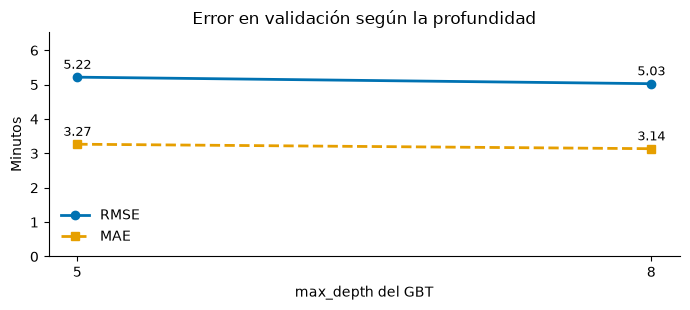

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(tuning["max_depth"], tuning["rmse"], color=OKABE_ITO["blue"], marker="o", linewidth=2, label="RMSE")
ax.plot(tuning["max_depth"], tuning["mae"], color=OKABE_ITO["orange"], marker="s", linestyle="--", linewidth=2, label="MAE")
for _, row in tuning.iterrows():
    ax.annotate(f"{row['rmse']:.2f}", (row["max_depth"], row["rmse"]), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=9)
    ax.annotate(f"{row['mae']:.2f}", (row["max_depth"], row["mae"]), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=9)
ax.set_xticks(tuning["max_depth"])
ax.set_xlabel("max_depth del GBT")
ax.set_ylabel("Minutos")
ax.set_ylim(0, tuning["rmse"].max() * 1.25)
ax.set_title("Error en validación según la profundidad")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


In [21]:
job_id = last_job_id()
with step("Entrenamiento GBT final"):
    gbt_model = Pipeline(stages=[
        assembler,
        GBTRegressor(labelCol="duration_min", featuresCol="features", maxDepth=best_depth, maxIter=80, stepSize=0.15, subsamplingRate=0.8, seed=SEED),
    ]).fit(train_sample)
gbt_jobs = jobs_since(job_id)

job_id = last_job_id()
with step("Entrenamiento regresión lineal"):
    lr_model = Pipeline(stages=[
        assembler,
        LinearRegression(labelCol="duration_min", featuresCol="features", regParam=0.01, elasticNetParam=0.0),
    ]).fit(train_sample)
lr_jobs = jobs_since(job_id)

pd.DataFrame(
    {"seconds": [timings["Entrenamiento GBT final"], timings["Entrenamiento regresión lineal"]], **pd.DataFrame([gbt_jobs, lr_jobs]).to_dict("list")},
    index=[f"GBT (max_depth={best_depth}, 80 árboles)", "Regresión lineal"],
).round(1)

Entrenamiento GBT final: 176.1 s


netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


Entrenamiento regresión lineal: 1.8 s


,seconds,jobs,tasks
"GBT (max_depth=8, 80 árboles)",176.1,643,65551
Regresión lineal,1.8,2,188


**Observación.** En la gráfica de validación, la profundidad 8 baja el RMSE de 5.22 a 5.03 minutos y el MAE de 3.27 a 3.14, así que la usé para el modelo final. MLlib no entrena un modelo por partición y luego los junta. Cada árbol del GBT se construye nivel por nivel. En cada nivel, cada una de las 12 particiones calcula histogramas de las variables para los nodos abiertos. Spark los combina con un `reduceByKey` (por eso hay shuffle) y el driver elige los mejores cortes. Por eso el GBT final lanzó 643 jobs y unas 65 mil tareas: son 80 árboles, varios niveles por árbol y la actualización de residuos en cada iteración. La regresión lineal es más simple. Con 14 variables, Spark usa las ecuaciones normales: cada partición calcula su parte de XᵀX y Xᵀy, el driver las suma y resuelve un sistema de 14 × 14. Fueron 2 jobs y menos de 2 segundos. Los avisos de `netlib` solo indican que no hay BLAS nativo y Spark usa su implementación en Java.

## 7. Evaluación y predicciones

Evalué los modelos con RegressionEvaluator sobre los 3,451,535 viajes de diciembre de 2024, que ningún modelo vio al entrenar. RMSE y MAE están en minutos.

In [22]:
with step("Evaluación en diciembre 2024"):
    gbt_test = gbt_model.transform(test_features).persist(StorageLevel.DISK_ONLY)
    results = pd.DataFrame([
        {"model": "Línea base de ruta", **evaluate(test_features.withColumn("prediction", F.col("route_duration_enc")))},
        {"model": "Regresión lineal", **evaluate(lr_model.transform(test_features))},
        {"model": f"GBT (max_depth={best_depth})", **evaluate(gbt_test)},
    ])
    results["test_rows"] = gbt_test.count()
results.to_csv(DASHBOARD_DIR / "model_metrics.csv", index=False)
results

Evaluación en diciembre 2024: 62.4 s


,model,rmse,mae,r2,test_rows
0,Línea base de ruta,9.3641,5.7438,0.6059,3451535
1,Regresión lineal,8.1931,5.3829,0.6983,3451535
2,GBT (max_depth=8),6.7765,4.1894,0.7936,3451535


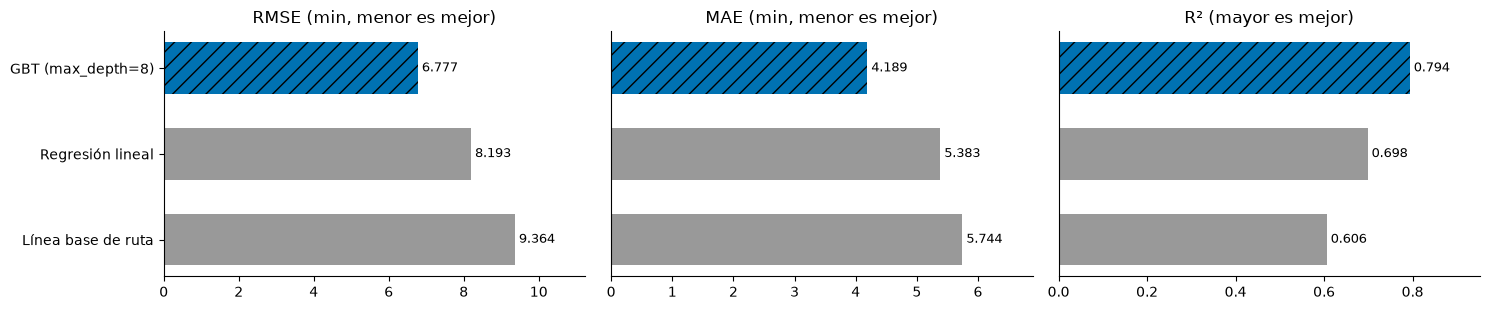

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
labels = {"rmse": "RMSE (min, menor es mejor)", "mae": "MAE (min, menor es mejor)", "r2": "R² (mayor es mejor)"}
for ax, metric in zip(axes, labels):
    ax.barh(results["model"], results[metric], color=[OKABE_ITO["grey"], OKABE_ITO["grey"], OKABE_ITO["blue"]], height=0.6)
    ax.patches[-1].set_hatch("//")
    for i, value in enumerate(results[metric]):
        ax.text(value, i, f" {value:.3f}", va="center", fontsize=9)
    ax.set_xlim(0, results[metric].max() * 1.2)
    ax.set_title(labels[metric])
for ax in axes[1:]:
    ax.set_yticks([])
plt.tight_layout()
plt.show()

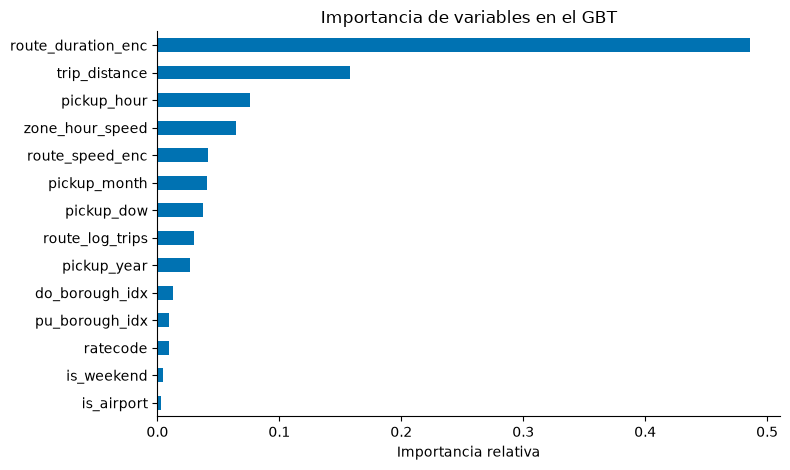

In [24]:
importances = pd.Series(gbt_model.stages[-1].featureImportances.toArray(), index=FEATURES).sort_values()
ax = importances.plot.barh(figsize=(8, 4.8), color=OKABE_ITO["blue"], title="Importancia de variables en el GBT")
ax.set_xlabel("Importancia relativa")
plt.tight_layout()
plt.show()

**Observación.** El GBT gana en las tres métricas (la barra con trama es el mejor modelo): RMSE de 6.78 contra 8.19 de la regresión lineal y 9.36 de la base por ruta. Contra la primera entrega, que solo usaba 2024, el RMSE del GBT bajó de 7.13 a 6.78 y el R² subió de 0.772 a 0.794. La base por ruta empeoró un poco (de 9.23 a 9.36) porque ahora promedia viajes de 2021, cuando el tráfico era más ligero. El GBT puede compensarlo con `pickup_year` y `pickup_month`, aunque esas variables pesan poco. La más importante es la duración promedio de la ruta (casi la mitad de la importancia), seguida de la distancia y la hora. `transform` aplica el modelo dentro de cada partición, sin shuffle, y cada métrica es una pasada sobre diciembre. Por eso persistí `gbt_test`, para no recalcular las predicciones en cada métrica.

### Predicciones de diciembre

In [25]:
gbt_test.select(
    "tpep_pickup_datetime", "pu_zone", "do_zone", "trip_distance",
    F.round("duration_min", 1).alias("actual_min"),
    F.round("prediction", 1).alias("predicted_min"),
    F.round(F.col("prediction") - F.col("duration_min"), 1).alias("error_min"),
).sample(fraction=0.00001, seed=7).limit(15).toPandas()

,tpep_pickup_datetime,pu_zone,do_zone,trip_distance,actual_min,predicted_min,error_min
0,2024-12-01 13:49:10,Midtown North,Garment District,0.90,9.7,10.9,1.3
1,2024-12-01 22:06:20,JFK Airport,Baisley Park,4.43,11.9,12.9,0.9
2,2024-12-02 12:17:27,Lincoln Square East,Upper East Side South,1.11,13.5,9.4,-4.1
3,2024-12-03 18:02:45,JFK Airport,Yorkville West,19.52,67.8,50.6,-17.2
4,2024-12-03 20:51:02,Lincoln Square East,Midtown East,1.93,14.5,16.4,1.9
5,2024-12-04 12:48:06,Upper West Side North,Upper West Side North,0.55,3.7,4.5,0.8
6,2024-12-08 17:32:07,Upper West Side South,Upper West Side North,0.70,7.2,4.2,-3.0
7,2024-12-08 20:14:22,Woodside,JFK Airport,12.24,23.7,33.7,10.0
8,2024-12-09 18:17:03,JFK Airport,Flushing,9.93,39.3,29.2,-10.0
9,2024-12-11 08:46:45,Kips Bay,Murray Hill,1.34,11.8,10.9,-0.8


Error por hora y muestra de predicciones: 1.7 s


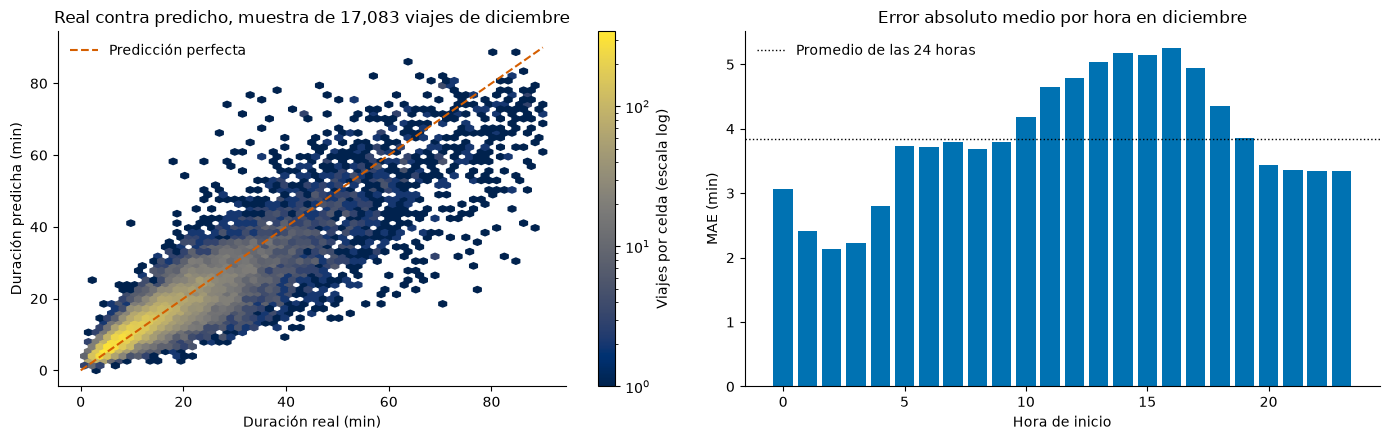

In [26]:
with step("Error por hora y muestra de predicciones"):
    error_by_hour = export_csv(
        gbt_test.withColumn("abs_error", F.abs(F.col("prediction") - F.col("duration_min")))
        .groupBy("pickup_hour").agg(
            F.count("*").alias("trips"),
            F.round(F.avg("duration_min"), 2).alias("avg_actual_min"),
            F.round(F.avg("prediction"), 2).alias("avg_predicted_min"),
            F.round(F.avg("abs_error"), 2).alias("mae_min"),
            F.round(F.sqrt(F.avg(F.pow(F.col("prediction") - F.col("duration_min"), 2))), 2).alias("rmse_min"),
        ).orderBy("pickup_hour"),
        "model_error_by_hour",
    )
    predictions_sample = export_csv(
        gbt_test.sample(fraction=0.005, seed=SEED).select(
            "tpep_pickup_datetime", "pu_zone", "do_zone", "pickup_hour", "trip_distance",
            F.round("duration_min", 2).alias("actual_min"), F.round("prediction", 2).alias("predicted_min"),
        ),
        "model_predictions_sample",
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
hb = axes[0].hexbin(predictions_sample["actual_min"], predictions_sample["predicted_min"], gridsize=60, bins="log", extent=(0, 90, 0, 90), cmap="cividis")
axes[0].plot([0, 90], [0, 90], color=OKABE_ITO["vermillion"], linestyle="--", linewidth=1.5, label="Predicción perfecta")
axes[0].legend(frameon=False, loc="upper left")
axes[0].set_xlabel("Duración real (min)")
axes[0].set_ylabel("Duración predicha (min)")
axes[0].set_title(f"Real contra predicho, muestra de {len(predictions_sample):,} viajes de diciembre")
fig.colorbar(hb, ax=axes[0], label="Viajes por celda (escala log)")
axes[1].bar(error_by_hour["pickup_hour"], error_by_hour["mae_min"], color=OKABE_ITO["blue"], width=0.8)
axes[1].axhline(error_by_hour["mae_min"].mean(), color="black", linestyle=":", linewidth=1, label="Promedio de las 24 horas")
axes[1].legend(frameon=False)
axes[1].set_xlabel("Hora de inicio")
axes[1].set_ylabel("MAE (min)")
axes[1].set_title("Error absoluto medio por hora en diciembre")
plt.tight_layout()
plt.show()

**Observación.** Los puntos siguen la diagonal punteada hasta unos 40 minutos. Arriba de eso, el modelo tiende a quedarse corto, como en el viaje de Penn Station a Upper East Side North de la tabla (20 minutos de error) o el de JFK a Yorkville West (17 minutos). El MAE por hora va de 2.1 minutos a las 2 h a más de 5 entre las 13 y las 16 h, cuando el tráfico es más variable; la línea punteada marca el promedio de las 24 horas (3.8 minutos). El agregado por hora y la muestra salieron de `gbt_test` persistido en menos de 2 segundos.

### Viajes nuevos

También probé rutas hipotéticas a distintas horas de diciembre de 2024.

In [27]:
scenarios = spark.createDataFrame(
    [
        ("JFK a Midtown, lunes 08:00", 132, 161, 17.0, 8, 1, 2),
        ("JFK a Midtown, lunes 17:00", 132, 161, 17.0, 17, 1, 2),
        ("JFK a Midtown, domingo 04:00", 132, 161, 17.0, 4, 7, 2),
        ("Upper East Side a Midtown, martes 09:00", 237, 161, 1.6, 9, 2, 1),
        ("Upper East Side a Midtown, sábado 23:00", 237, 161, 1.6, 23, 6, 1),
    ],
    "scenario string, PULocationID int, DOLocationID int, trip_distance double, pickup_hour int, pickup_dow int, ratecode int",
)
scenarios = (
    scenarios.withColumn("is_weekend", (F.col("pickup_dow") >= 6).cast("int"))
    .withColumn("is_airport", (F.col("PULocationID").isin(AIRPORT_ZONES) | F.col("DOLocationID").isin(AIRPORT_ZONES)).cast("int"))
    .withColumn("pickup_year", F.lit(2024))
    .withColumn("pickup_month", F.lit(12))
    .join(pu_zones, "PULocationID").join(do_zones, "DOLocationID")
    .withColumn("tpep_pickup_datetime", F.lit(None).cast("timestamp"))
    .withColumn("duration_min", F.lit(None).cast("double"))
)
scenario_preds = gbt_model.transform(add_model_features(scenarios)).select(
    "scenario", "pu_zone", "do_zone", "trip_distance", F.round("prediction", 1).alias("predicted_min")
).toPandas()
scenario_preds

,scenario,pu_zone,do_zone,trip_distance,predicted_min
0,"JFK a Midtown, lunes 08:00",JFK Airport,Midtown Center,17.0,63.4
1,"JFK a Midtown, lunes 17:00",JFK Airport,Midtown Center,17.0,61.8
2,"JFK a Midtown, domingo 04:00",JFK Airport,Midtown Center,17.0,34.2
3,"Upper East Side a Midtown, martes 09:00",Upper East Side South,Midtown Center,1.6,16.5
4,"Upper East Side a Midtown, sábado 23:00",Upper East Side South,Midtown Center,1.6,24.4


**Observación.** De JFK a Midtown, el modelo estima unos 62 a 63 minutos un lunes a las 8 o a las 17 h y 34 minutos un domingo a las 4 h, lo que coincide con las velocidades del mapa de calor. Para el viaje corto de Upper East Side a Midtown estima 16.5 minutos un martes a las 9 h, pero 24.4 minutos un sábado a las 23 h. Eso no cuadra con el mapa de calor, donde el sábado en la noche es más rápido. Lo tomo como una señal de que el modelo se equivoca en combinaciones de ruta, hora y día con pocos viajes parecidos; antes de usarlo en serio revisaría esos casos.

## 8. Cómo se repartió el trabajo

Al final consulté la API REST de la interfaz de Spark (`/api/v1/applications/.../stages`) para ver todas las etapas que se ejecutaron. Cada acción importante tiene una descripción de job, así que pude agrupar las etapas por paso.

In [28]:
stages = pd.DataFrame(spark_api("stages?status=complete"))
for col in ["submissionTime", "completionTime"]:
    stages[col] = pd.to_datetime(stages[col].str.replace("GMT", "", regex=False))
stages["seconds"] = (stages["completionTime"] - stages["submissionTime"]).dt.total_seconds()
stages["step"] = stages.get("description", pd.Series(index=stages.index, dtype=object)).fillna("Otras acciones")

print(f"stages: {len(stages)}, tasks: {stages['numTasks'].sum():,}")
print(f"shuffle write: {stages['shuffleWriteBytes'].sum() / 1e6:.1f} MB, spilled to disk: {stages['diskBytesSpilled'].sum() / 1e6:.1f} MB")
(
    stages.groupby("step").agg(
        stages=("stageId", "count"),
        tasks=("numTasks", "sum"),
        stage_seconds=("seconds", "sum"),
        input_rows_m=("inputRecords", lambda s: s.sum() / 1e6),
        shuffle_write_mb=("shuffleWriteBytes", lambda s: s.sum() / 1e6),
        shuffle_read_mb=("shuffleReadBytes", lambda s: s.sum() / 1e6),
        spill_disk_mb=("diskBytesSpilled", lambda s: s.sum() / 1e6),
    )
    .reindex([s for s in timings if s in set(stages["step"])] + (["Otras acciones"] if "Otras acciones" in set(stages["step"]) else []))
    .round(1)
)

stages: 2529, tasks: 32,011
shuffle write: 1416.2 MB, spilled to disk: 5665.1 MB


,stages,tasks,stage_seconds,input_rows_m,shuffle_write_mb,shuffle_read_mb,spill_disk_mb
step,,,,,,,
Conteo de filas por archivo,2,193,4.1,150.0,0.0,0.0,0.0
Perfil de calidad,2,193,19.6,150.0,0.0,0.0,0.0
Limpieza y escritura Parquet,2,193,141.7,150.0,0.0,0.0,5665.1
Lectura de diciembre 2024 con poda de particiones,2,5,0.1,3.5,0.0,0.0,0.0
Persistir viajes limpios,3,157,109.2,143.1,0.0,0.0,0.0
Agregado diario 2021-2024,4,81,7.1,0.0,0.3,0.5,0.0
Agregados del tablero 2024,19,408,27.3,0.1,53.6,55.0,0.0
Agregados de varios años,6,160,10.3,0.0,0.2,0.2,0.0
Codificaciones por ruta y zona-hora,14,523,22.8,0.1,45.7,45.7,0.0


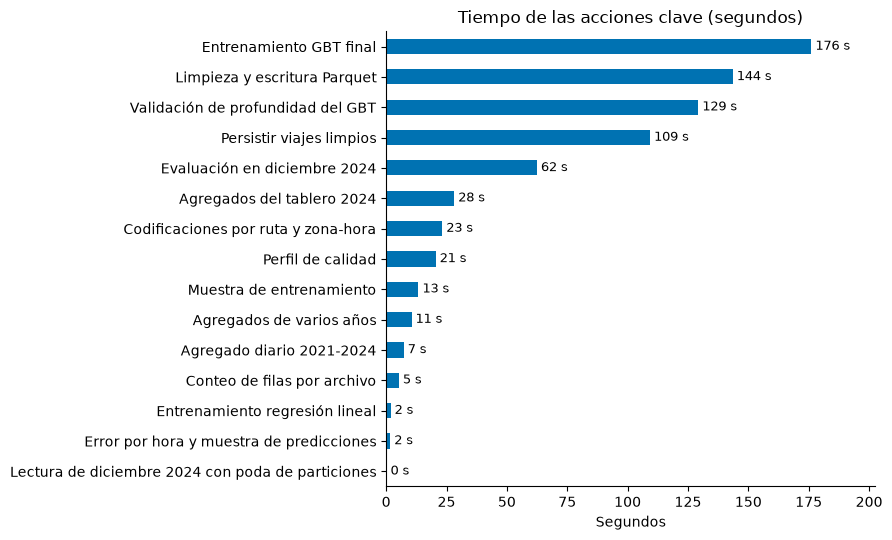

In [29]:
timing_series = pd.Series(timings).sort_values()
ax = timing_series.plot.barh(figsize=(9, 5.5), color=OKABE_ITO["blue"], title="Tiempo de las acciones clave (segundos)")
for i, value in enumerate(timing_series):
    ax.text(value, i, f" {value:.0f} s", va="center", fontsize=9)
ax.set_xlim(0, timing_series.max() * 1.15)
ax.set_xlabel("Segundos")
plt.tight_layout()
plt.show()

**Observación.** La aplicación completó 2,529 etapas y 32,011 tareas. La columna `input_rows_m` confirma que el conteo, el perfil y la limpieza leyeron las 150.0 M filas de los 48 archivos, y que la persistencia leyó las 143.1 M filas limpias. Esos pasos tienen pocas etapas, muchas tareas y nada de shuffle, porque los filtros, las columnas nuevas y las uniones broadcast se resuelven dentro de cada partición. El único spill a disco (unos 5.7 GB) fue en la escritura. Con `partitionBy`, cada tarea ordena sus filas por año y mes antes de escribir, y con 4 tareas a la vez en 4 GB de memoria ese ordenamiento no cupo. Los agregados movieron entre 0.2 y 54 MB gracias a la agregación parcial, y la consulta de diciembre solo leyó 3.5 M filas por la poda de particiones. Casi todas las etapas (2,350 de 2,529) y el 77 % del shuffle (1.1 GB de 1.4 GB) vienen del GBT, porque cada nivel de cada árbol es una ronda de histogramas sobre las 12 particiones. Por eso su columna de entrada suma miles de millones de filas: es la misma muestra de 2.1 M filas leída del caché cientos de veces. En la gráfica de tiempos, lo más caro fue el entrenamiento del GBT (176 s), seguido de la limpieza (144 s), la validación (129 s) y la persistencia (109 s). `Otras acciones` son las acciones sin descripción, como `summary()` y las tablas de ejemplo.

## 9. Conclusión

Con cuatro años de datos (48 archivos Parquet, 2.42 GB, 150.0 M viajes leídos y 143.1 M limpios), el flujo completo corrió en 14 minutos en una laptop con Spark local, 4 núcleos y 4 GB para el driver. El GBT tuvo el menor error en diciembre de 2024. Obtuve estas métricas (RMSE / MAE / R²): GBT 6.7765 / 4.1894 / 0.7936; lineal 8.1931 / 5.3829 / 0.6983; base por ruta 9.3641 / 5.7438 / 0.6059. No usé diciembre para elegir el modelo. Lo más caro fue entrenar el GBT y limpiar los datos crudos. Si el volumen siguiera creciendo, reescribiría los Parquet crudos con varios row groups por archivo para que Spark pudiera leerlos con más de 48 tareas, y correría en una máquina con más memoria para tener el caché en RAM. También me faltaría probar variables de clima y días festivos, y revisar los casos raros de la sección 7.

In [30]:
spark.stop()

## 10. Tablero

[Tablero Taxis NYC 2024](https://public.tableau.com/app/profile/facundo.bautista.barber./viz/Modulo6TaxisNYCPySpark/TableroTaxisNYC2024)

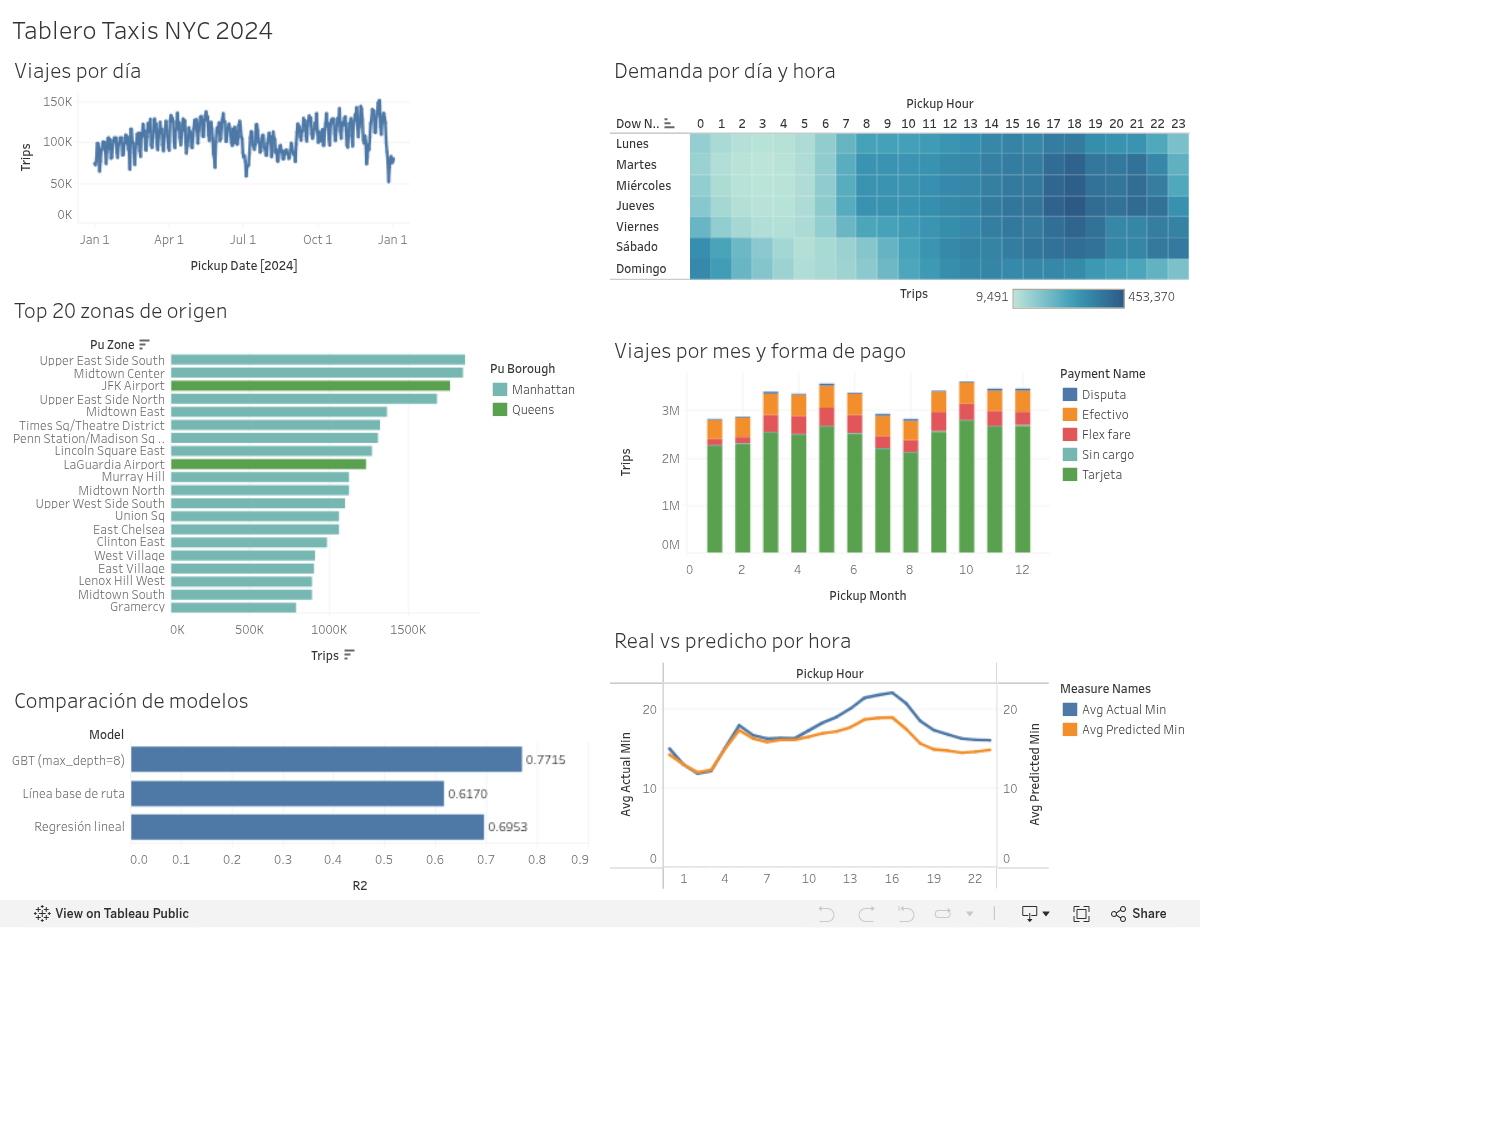

El tablero publicado usa los CSV de 2024 de la primera entrega. Los paneles de viajes, demanda, zonas y formas de pago siguen siendo válidos: con el nuevo rango de fechas los CSV de 2024 solo cambian en 4 viajes de 39 millones. Los paneles "Comparación de modelos" y "Real vs predicho por hora" muestran el modelo de la primera entrega (GBT con R² de 0.7715). Los CSV del modelo nuevo (`model_metrics.csv` y `model_error_by_hour.csv`) están en `dashboard/`, junto a este notebook, para volver a publicar esos dos paneles.